# Section 1: Algorithms

## Question 1 (Predator-Prey Model)

### Algorithm

1. Define the rate constants $\alpha = 1.5$, $\beta = 1.0$, $\gamma = 3.0$, and $\delta = 1.0$.
2. Define the starting populations $r_0 = 0.1$ (rabbits) and $f_0 = 0.3$ (foxes).
3. Set maximum simulation time $t_{\text{max}} = 60.0$, CFL factor $C = 0.00005$, and dynamically calculate the time step $\Delta t = C / \max(\alpha, \gamma)$.
4. Generate the discrete time array from $0$ to $t_{\text{max}}$ with step size $\Delta t$, and determine the total number of integration steps $N$.
5. Define the set of initial pairs $(r_0, f_0)$ to test in phase space: $(0.01, 2.0)$, $(1.0, 1.0)$, $(2.0, 2.0)$, and $(1.5, 1.5)$.
6. Create zero-initialized NumPy arrays $r$ and $f$ of length $N$.
7. Set $r[0] = r_0$ and $f[0] = f_0$.
8. Iterate index $i$ from $1$ to $N - 1$ using the forward Euler method:
* Calculate rabbit rate of change: $\dot{r} = \alpha \cdot r[i-1] - \beta \cdot r[i-1] \cdot f[i-1]$.
* Calculate fox rate of change: $\dot{f} = -\gamma \cdot f[i-1] + \delta \cdot r[i-1] \cdot f[i-1]$.
* Update values: $r[i] = r[i-1] + \dot{r} \cdot \Delta t$ and $f[i] = f[i-1] + \dot{f} \cdot \Delta t$.
9. Plot population trajectories $r(t)$ and $f(t)$ against time $t$.
10. Phase-Space Trajectory Loop: For each pair $(r_0, f_0)$ in the testing list:
* Re-initialize arrays $r_{\text{traj}}$ and $f_{\text{traj}}$ of length $N$ with $r_{\text{traj}}[0] = r_0$ and $f_{\text{traj}}[0] = f_0$.
* Execute the numerical integration loop from $i = 1$ to $N - 1$ using the defined rate formulas.
* Plot the trajectory curve: $r_{\text{traj}}$ (X-axis) vs. $f_{\text{traj}}$ (Y-axis).
11. Plot and Label Fixed Points:
* Origin: $(0, 0)$
* Coexistence: $\left(\frac{\gamma}{\delta}, \frac{\alpha}{\beta}\right)$


## Question 2 (Rabbit–Sheep Competition Model)

### Algorithm

1. Define the rate constants $A = 3.0$, $B = 2.0$, $C = 1.0$, $D = 2.0$, $E = 1.0$, and $F = 1.0$.
2. Define starting populations $r_0 = 0.1$ (rabbits) and $s_0 = 0.3$ (sheep).
3. Set maximum simulation time $t_{\text{max}} = 60.0$, CFL factor $\text{CFL} = 0.00005$, and compute $\Delta t = \text{CFL} / \max(A, B, C, D, E, F)$.
4. Generate the continuous time array from $0$ to $t_{\text{max}}$ with step size $\Delta t$, and determine the total number of steps $N$.
5. Define the initial condition pairs $(r_0, s_0)$ to test in phase space: $(0.01, 2.0)$, $(1.0, 1.0)$, $(2.0, 2.0)$, and $(1.5, 1.5)$.
6. Create zero-initialized NumPy arrays $r$ and $s$ of length $N$.
7. Set $r[0] = r_0$ and $s[0] = s_0$.
8. Iterate index $i$ from $1$ to $N - 1$ using the forward Euler method:
* Calculate rabbit rate of change: $\dot{r} = A \cdot s[i-1] - B \cdot r[i-1] \cdot s[i-1] - C \cdot (r[i-1])^2$.
* Calculate sheep rate of change: $\dot{s} = D \cdot r[i-1] + E \cdot r[i-1] \cdot s[i-1] - F \cdot (s[i-1])^2$.
* Update values: $r[i] = r[i-1] + \dot{r} \cdot \Delta t$ and $s[i] = s[i-1] + \dot{s} \cdot \Delta t$.
9. Plot population trajectories $r(t)$ and $s(t)$ against time $t$.
10. For each pair $(r_0, s_0)$ in the testing list:
* Re-initialize arrays $r_{\text{traj}}$ and $s_{\text{traj}}$ of length $N$ with $r_{\text{traj}}[0] = r_0$ and $s_{\text{traj}}[0] = s_0$.
* Execute the rate of change integration loop from $i = 1$ to $N - 1$.
* Plot the trajectory curve: $r_{\text{traj}}$ (X-axis) vs. $s_{\text{traj}}$ (Y-axis).
11. Plot and Label Fixed Points:
* Origin: $(0, 0)$
* Coexistence: $(r^*,s^*)$
$$r^* = \frac{A \cdot k}{B \cdot k + C} \quad \text{and} \quad s^* = k \cdot r^*$$
* where $$k = \frac{E + \sqrt{E^2 + 4DF}}{2F}$$  

# Section 2: Code and Outputs

## Question 1 (Rabbit-Fox)

### Code and Output

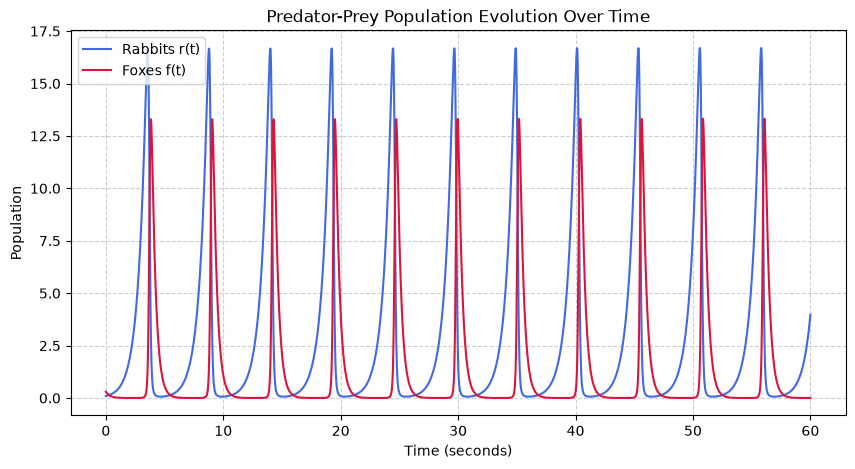

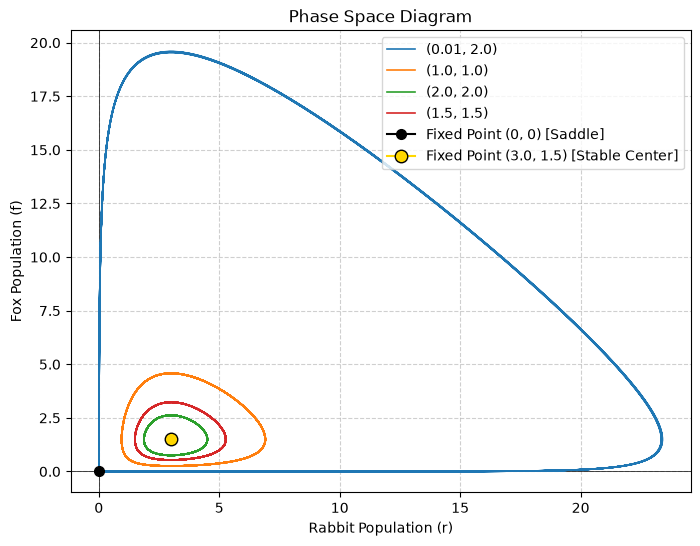

In [5]:
import matplotlib.pyplot as plt
import numpy as np

# PARAMETERS
alpha = 1.5  # Rabbit growth rate
beta = 1.0  # Rabbit decay rate
gamma = 3.0  # Fox decay rate
delta = 1.0  # Fox growth

C = 0.00005  # CFL factor
dt = C / max(alpha, gamma)

t_max = 60.0
time_array = np.arange(0, t_max, dt)
n_pop = len(time_array)

# OUTPUT 1: TIME EVOLUTION PLOT
r = np.zeros(n_pop)
f = np.zeros(n_pop)
r[0] = 0.1
f[0] = 0.3

for i in range(1, n_pop):
    r_dot = alpha * r[i - 1] - beta * r[i - 1] * f[i - 1]
    f_dot = -gamma * f[i - 1] + delta * r[i - 1] * f[i - 1]

    r[i] = r[i - 1] + r_dot * dt
    f[i] = f[i - 1] + f_dot * dt

plt.figure(1, figsize=(10, 5))
plt.plot(time_array, r, label="Rabbits r(t)", color="royalblue", lw=1.5)
plt.plot(time_array, f, label="Foxes f(t)", color="crimson", lw=1.5)
plt.title("Predator-Prey Population Evolution Over Time")
plt.xlabel("Time (seconds)")
plt.ylabel("Population")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

# OUTPUT 2: PHASE SPACE DIAGRAM
values_to_test = [(0.01, 2.0), (1.0, 1.0), (2.0, 2.0), (1.5, 1.5)]

plt.figure(2, figsize=(8, 6))
plt.title("Phase Space Diagram")
plt.xlabel("Rabbit Population (r)")
plt.ylabel("Fox Population (f)")
plt.axhline(0, color="black", linewidth=0.5)
plt.axvline(0, color="black", linewidth=0.5)
plt.grid(True, linestyle="--", alpha=0.6)

for r0, f0 in values_to_test:
    r_traj = np.zeros(n_pop)
    f_traj = np.zeros(n_pop)
    r_traj[0] = r0
    f_traj[0] = f0

    for i in range(1, n_pop):
        r_dot = alpha * r_traj[i - 1] - beta * r_traj[i - 1] * f_traj[i - 1]
        f_dot = -gamma * f_traj[i - 1] + delta * r_traj[i - 1] * f_traj[i - 1]

        r_traj[i] = r_traj[i - 1] + r_dot * dt
        f_traj[i] = f_traj[i - 1] + f_dot * dt

    plt.plot(r_traj, f_traj, label=f"({r0}, {f0})", lw=1.2)

# Highlight fixed points
plt.plot(
    0,
    0,
    marker="o",
    color="black",
    markersize=7,
    label="Fixed Point (0, 0) [Saddle]",
)
plt.plot(
    gamma / delta,
    alpha / beta,
    marker="o",
    color="gold",
    markeredgecolor="black",
    markersize=9,
    label=f"Fixed Point ({gamma / delta}, {alpha / beta}) [Stable Center]",
)

plt.legend()
plt.show()


## Question 2 (Rabbit-Sheep)

### Code and Output

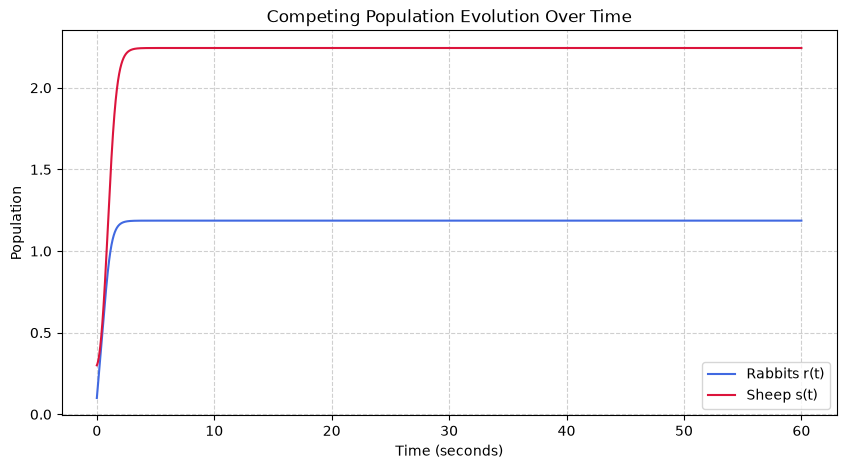

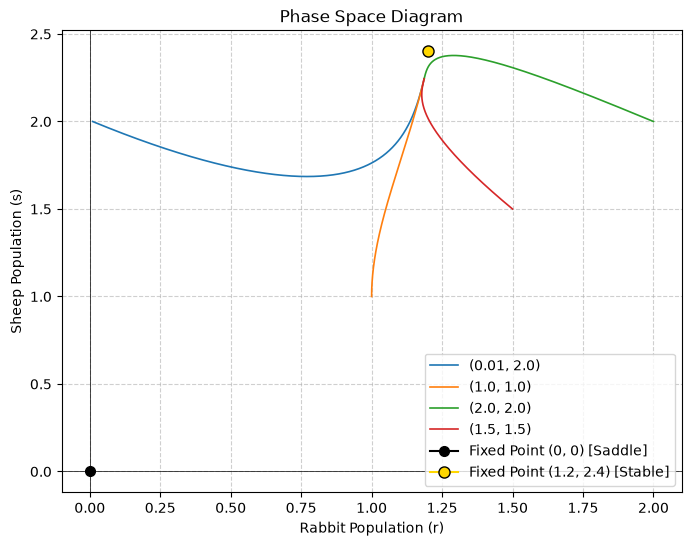

In [6]:
import matplotlib.pyplot as plt
import numpy as np

# PARAMETERS
A = 3.0
B = 2.0
C = 1.0
D = 2.0
E = 1.0
F = 1.0

CFL = 0.00005  # CFL factor
dt = CFL / max(A, B, C, D, E, F)

t_max = 60.0
time_array = np.arange(0, t_max, dt)
n_pop = len(time_array)

# OUTPUT 1: TIME EVOLUTION PLOT
r = np.zeros(n_pop)
s = np.zeros(n_pop)
r[0] = 0.1
s[0] = 0.3

for i in range(1, n_pop):
    r_dot = A * s[i - 1] - B * r[i - 1] * s[i - 1] - C * (r[i - 1] ** 2)
    s_dot = D * r[i - 1] + E * r[i - 1] * s[i - 1] - F * (s[i - 1] ** 2)

    r[i] = r[i - 1] + r_dot * dt
    s[i] = s[i - 1] + s_dot * dt

plt.figure(1, figsize=(10, 5))
plt.plot(time_array, r, label="Rabbits r(t)", color="royalblue", lw=1.5)
plt.plot(time_array, s, label="Sheep s(t)", color="crimson", lw=1.5)
plt.title("Competing Population Evolution Over Time")
plt.xlabel("Time (seconds)")
plt.ylabel("Population")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

# OUTPUT 2: PHASE SPACE DIAGRAM
values_to_test = [(0.01, 2.0), (1.0, 1.0), (2.0, 2.0), (1.5, 1.5)]

plt.figure(2, figsize=(8, 6))
plt.title("Phase Space Diagram")
plt.xlabel("Rabbit Population (r)")
plt.ylabel("Sheep Population (s)")
plt.axhline(0, color="black", linewidth=0.5)
plt.axvline(0, color="black", linewidth=0.5)
plt.grid(True, linestyle="--", alpha=0.6)

for r0, s0 in values_to_test:
    r_traj = np.zeros(n_pop)
    s_traj = np.zeros(n_pop)
    r_traj[0] = r0
    s_traj[0] = s0

    for i in range(1, n_pop):
        r_dot = (
            A * s_traj[i - 1]
            - B * r_traj[i - 1] * s_traj[i - 1]
            - C * (r_traj[i - 1] ** 2)
        )
        s_dot = (
            D * r_traj[i - 1]
            + E * r_traj[i - 1] * s_traj[i - 1]
            - F * (s_traj[i - 1] ** 2)
        )

        r_traj[i] = r_traj[i - 1] + r_dot * dt
        s_traj[i] = s_traj[i - 1] + s_dot * dt

    plt.plot(r_traj, s_traj, label=f"({r0}, {s0})", lw=1.2)

# Highlight fixed points
plt.plot(
    0,
    0,
    marker="o",
    color="black",
    markersize=7,
    label="Fixed Point (0, 0) [Saddle]",
)

k = (E + np.sqrt(E**2 + 4 * D * F)) / (2 * F)
r_f = (A * k) / (B * k + C)
s_f = k * r_f
plt.plot(
    r_f,
    s_f,
    marker="o",
    color="gold",
    markeredgecolor="black",
    markersize=8,
    label=f"Fixed Point ({r_f:.1f}, {s_f:.1f}) [Stable]",
)

plt.legend()
plt.show()


# Section 3

## Question 1 (Rabbit-Fox)

**Answer:** The predator-prey model ($\dot{r} = \alpha r - \beta r f$, $\dot{f} = -\gamma f + \delta r f$) has two fixed points found by setting $\dot{r} = 0$ and $\dot{f} = 0$:

a. **Extinction Point** $(0, 0)$:

* Since for this case, the eigenvalues have opposite signs, the origin is a **saddle point**.

b. **Coexistence Point** $\left(\frac{\gamma}{\delta}, \frac{\alpha}{\beta}\right) = (3.0, 1.5)$:

* Since this case results in purely imaginary eigenvalues, it indicate a **stable center**, where trajectories form closed periodic orbits circulating indefinitely around $(3.0, 1.5)$ rather than decaying inward or diverging outward.


## Question 2 (Rabbit-Sheep)

**Answer:** i) The competing species model ($\dot{r} = A s - B r s - C r^2$, $\dot{s} = D r + E r s - F s^2$) with parameters $(A, B, C, D, E, F) = (3.0, 2.0, 1.0, 2.0, 1.0, 1.0)$ has two fixed points found by setting $\dot{r} = 0$ and $\dot{s} = 0$:

a. **Extinction Point $(0, 0)$:**

* Since for this case, the eigenvalues are real with opposite signs, the origin is a **saddle point**.

b. **Coexistence Point $(1.2, 2.4)$:**

* Since for this case, both eigenvalues are strictly negative and real, this point is **stable**. All trajectories starting in the interior of the phase space converge directly into $(1.2, 2.4)$ over time.


ii) The zero-growth curves ($s = \frac{r^2}{3 - 2r}$ for $\dot{r} = 0$, and $s = 2r$ for $\dot{s} = 0$) partition the phase space into four directional flow quadrants.
Also, since coexistence point $(1.2, 2.4)$ is a **stable point**. Trajectories across all four regions flow inward and settle at $(1.2, 2.4)$.


## Additional Questions

### Question 1

**Answer:** Setting the rates to zero ($\dot{r} = 0, \dot{f} = 0$) yields two fixed points whose locations depend on the rate parameters:

* **Extinction Point $(0, 0)$:** Independent of parameter values, fixed at the origin.

* **Coexistence Point $(r^*, f^*) = \left(\frac{\gamma}{\delta}, \frac{\alpha}{\beta}\right)$:**

* The **equilibrium rabbit population ($r^* = \gamma/\delta$)** depends solely on predator parameters that is the ratio of fox mortality rate ($\gamma$) to fox hunting efficiency ($\delta$).

* The **equilibrium fox population ($f^* = \alpha/\beta$)** depends solely on prey parameters that is the ratio of rabbit natural growth rate ($\alpha$) to rabbit death rate ($\beta$).


### Question 2

**Answer:** In the competing species model ($\dot{r} = A s - B r s - C r^2$, $\dot{s} = D r + E r s - F s^2$), one population always dominates when inter-species competition dominates over intra-species self-limitation:

* **Rabbit Dominance ($r$ wins, $s \to 0$):** Occurs when rabbit self-limitation ($C$) is small compared to sheep competition parameters, and rabbits heavily suppress sheep growth.

* **Sheep Dominance ($s$ wins, $r \to 0$):** Occurs when sheep self-limitation ($F$) is small and sheep exert strong competitive suppression on rabbits ($B \gg E$).



### Question 3

**Answer:** 

What I Learned:

* **Predator-Prey Dynamics:** Coupled differential equations govern the time evolution of rabbit and fox populations. The system has a saddle fixed point at the origin $(0, 0)$ and a stable center at $(\gamma/\delta, \alpha/\beta) = (3.0, 1.5)$, where populations cycle in closed periodic orbits determined by their growth, predation, and death rates.

* **Resource Competition Dynamics:** Inter and intra-species competition over finite resources using sheep and rabbit systems. The system has a saddle fixed point at the origin $(0, 0)$ and a stable fixed point at the coexistence point $(1.2, 2.4)$. Zero-growth curves divide the phase space into directional flow regions converging toward equilibrium.

* **Competitive Exclusion & Dominance:** Variations in inter-species interaction parameters versus intra-species self-limitation determine whether two competing species sustainably coexist or if one population strictly dominates and drives the other to extinction.
